# 2D Conformal Coordinate Transformation (Cassini to UTM)

Least-squares estimation of four-parameter similarity parameters from Cassini control points to UTM eastings and northings, followed by residual, RMSE, and visual accuracy assessment.

In [3]:
# Import Packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import matplotlib.patches as patches

np.set_printoptions(precision=6, suppress=True)

# DATA INPUT 

In [5]:
# Training Points
train_points = [
    ('A', -363303.9, -124356.2, 9962251.2, 166700.7),
    ('B', -363127.9, -235694.9, 9928288.3, 166764.6),
    ('C', -359263.6, -385586.0, 9882566.3, 167967.4),
    ('D', -357677.4, -278604.1, 9915200.1, 168433.2),
    ('E', -356566.9, -56019.3, 9983096.8, 168753.0),
    ('F', -356564.3, -56012.2, 9983099.0, 168753.8),
    ('G', -353603.5, -744433.2, 9773106.3, 169798.0)
]

# Testing Points
test_points = [
    ('H', -343173.8, -151618.4, 9953936.6, 172844.0),
    ('I', -342363.3, -675601.0, 9794106.5, 173202.1),
    ('J', -341757.9, -196145.9, 9940354.5, 173279.9)
]

# Extract data into separate arrays
train_labels = [p[0] for p in train_points]
cassini_train = np.array([[p[1], p[2]] for p in train_points])
utm_train = np.array([[p[3], p[4]] for p in train_points])

test_labels = [p[0] for p in test_points]
cassini_test = np.array([[p[1], p[2]] for p in test_points])
utm_test = np.array([[p[3], p[4]] for p in test_points])

print("\n" + "-" * 60)
print("DATA SUMMARY")
print("-" * 60)
print(f"\nTraining Points: {len(train_labels)}")
print(f"Testing Points: {len(test_labels)}")

print("\nTraining Points (Cassini X, Cassini Y, UTM E, UTM N):")
print("-" * 80)
for i, label in enumerate(train_labels):
    print(f"{label}: ({cassini_train[i][0]:.1f}, {cassini_train[i][1]:.1f}) -> ({utm_train[i][0]:.1f}, {utm_train[i][1]:.1f})")

print("\nTesting Points:")
print("-" * 80)
for i, label in enumerate(test_labels):
    print(f"{label}: ({cassini_test[i][0]:.1f}, {cassini_test[i][1]:.1f}) -> ({utm_test[i][0]:.1f}, {utm_test[i][1]:.1f})")


------------------------------------------------------------
DATA SUMMARY
------------------------------------------------------------

Training Points: 7
Testing Points: 3

Training Points (Cassini X, Cassini Y, UTM E, UTM N):
--------------------------------------------------------------------------------
A: (-363303.9, -124356.2) -> (9962251.2, 166700.7)
B: (-363127.9, -235694.9) -> (9928288.3, 166764.6)
C: (-359263.6, -385586.0) -> (9882566.3, 167967.4)
D: (-357677.4, -278604.1) -> (9915200.1, 168433.2)
E: (-356566.9, -56019.3) -> (9983096.8, 168753.0)
F: (-356564.3, -56012.2) -> (9983099.0, 168753.8)
G: (-353603.5, -744433.2) -> (9773106.3, 169798.0)

Testing Points:
--------------------------------------------------------------------------------
H: (-343173.8, -151618.4) -> (9953936.6, 172844.0)
I: (-342363.3, -675601.0) -> (9794106.5, 173202.1)
J: (-341757.9, -196145.9) -> (9940354.5, 173279.9)


In [6]:
# Task 1: Store coordinates using NumPy arrays

print("\n" + "-" * 60)
print("TASK 1: STORE COORDINATES USING NUMPY ARRAYS")
print("-" * 60)

print("\nCassini Training Coordinates (7 points):")
print(cassini_train)
print(f"Shape: {cassini_train.shape}")

print("\nUTM Training Coordinates (7 points):")
print(utm_train)
print(f"Shape: {utm_train.shape}")

print("\nCassini Testing Coordinates (3 points):")
print(cassini_test)
print(f"Shape: {cassini_test.shape}")

print("\nUTM Testing Coordinates (3 points):")
print(utm_test)
print(f"Shape: {utm_test.shape}")


------------------------------------------------------------
TASK 1: STORE COORDINATES USING NUMPY ARRAYS
------------------------------------------------------------

Cassini Training Coordinates (7 points):
[[-363303.9 -124356.2]
 [-363127.9 -235694.9]
 [-359263.6 -385586. ]
 [-357677.4 -278604.1]
 [-356566.9  -56019.3]
 [-356564.3  -56012.2]
 [-353603.5 -744433.2]]
Shape: (7, 2)

UTM Training Coordinates (7 points):
[[9962251.2  166700.7]
 [9928288.3  166764.6]
 [9882566.3  167967.4]
 [9915200.1  168433.2]
 [9983096.8  168753. ]
 [9983099.   168753.8]
 [9773106.3  169798. ]]
Shape: (7, 2)

Cassini Testing Coordinates (3 points):
[[-343173.8 -151618.4]
 [-342363.3 -675601. ]
 [-341757.9 -196145.9]]
Shape: (3, 2)

UTM Testing Coordinates (3 points):
[[9953936.6  172844. ]
 [9794106.5  173202.1]
 [9940354.5  173279.9]]
Shape: (3, 2)


# **Construct Design Matrix (A) and Observation Vector (L)**
## Explanation:
 ### The 2D conformal transformation has 4 parameters: a, b, Tx, Ty
 #### For each point, we have two equations:
   #### E = a*x - b*y + Tx  (Easting equation)
   #### N = b*x + a*y + Ty  (Northing equation)

 ### Design Matrix A: Contains coefficients of the unknown parameters
   #### Row format for each point: [x, -y, 1, 0] for Easting
                             [y,  x, 0, 1] for Northing

 ##### Observation Vector L: Contains the observed UTM coordinates
   Format: [E1, N1, E2, N2, ..., En, Nn]

In [7]:
# Build A and L for 2D conformal transformation
A = []
L = []

for (x, y), (E, N) in zip(cassini_train, utm_train):
    # For Easting equation: E = a*x - b*y + Tx
    A.append([x, -y, 1, 0])
    # For Northing equation: N = b*x + a*y + Ty
    A.append([y, x, 0, 1])
    L.extend([E, N])

A = np.array(A, dtype=float)
L = np.array(L, dtype=float).reshape(-1, 1)

print("-" * 60)
print("TASK 2: CONSTRUCT DESIGN MATRIX (A) AND OBSERVATION VECTOR (L)")
print("-" * 60)

print(f"\nDesign Matrix A shape: {A.shape}")
print(f"Observation Vector L shape: {L.shape}")

# Display first few rows
print("\nFirst 4 rows of A:")
print(A[:4, :])
print("\nFirst 4 rows of L:")
print(L[:4, :])

------------------------------------------------------------
TASK 2: CONSTRUCT DESIGN MATRIX (A) AND OBSERVATION VECTOR (L)
------------------------------------------------------------

Design Matrix A shape: (14, 4)
Observation Vector L shape: (14, 1)

First 4 rows of A:
[[-363303.9  124356.2       1.        0. ]
 [-124356.2 -363303.9       0.        1. ]
 [-363127.9  235694.9       1.        0. ]
 [-235694.9 -363127.9       0.        1. ]]

First 4 rows of L:
[[9962251.2]
 [ 166700.7]
 [9928288.3]
 [ 166764.6]]


#  **Solve for a, b, Tx and Ty using Least Squares**
## Explanation:
 ### The least squares solution minimizes the sum of squared residuals:
   #### V = A*X - L  (residuals)
   #### X = (A^T * A)^-1 * A^T * L  (normal equation solution)

 #### This gives us the optimal parameters that minimize the squared errors between computed and observed UTM coordinates.

In [8]:
# Least squares solution: X = (A^T * A)^-1 * A^T * L
N_matrix = A.T @ A
U_matrix = A.T @ L
X = np.linalg.inv(N_matrix) @ U_matrix

# Extract parameters
a, b, Tx, Ty = X.flatten()

print("-" * 60)
print("TASK 3: SOLVE USING LEAST SQUARES")
print("-" * 60)

print("\nLeast Squares Solution:")
print("-" * 40)
print(f"a  = {a:.10f}")
print(f"b  = {b:.10f}")
print(f"Tx = {Tx:.10f}")
print(f"Ty = {Ty:.10f}")

# Verify by checking residuals
V = A @ X - L
print(f"\nResiduals (V):")
print(V.flatten())
print(f"\nSum of squared residuals: {np.sum(V**2):.6f}")
print(f"Variance of unit weight (σ₀²): {np.sum(V**2) / (len(L) - len(X)):.6f}")

------------------------------------------------------------
TASK 3: SOLVE USING LEAST SQUARES
------------------------------------------------------------

Least Squares Solution:
----------------------------------------
a  = -0.0041317092
b  = -0.3049000469
Tx = 9998666.3261096999
Ty = 57724.0393631916

Residuals (V):
[   -0.019021  2308.519177    14.978945  2650.975905    19.20936
   889.257098    -2.358029  -502.193462   -37.530331 -2080.24064
   -37.576283 -2081.862715    43.295358 -1184.455363]

Sum of squared residuals: 23469692.417730
Variance of unit weight (σ₀²): 2346969.241773


# **Compute scale factor and rotation angle**
## Explanation:
 #### From the 2D conformal transformation:
   a = s * cos(θ)  and  b = s * sin(θ)
 
### Therefore:
   #### Scale factor s = √(a² + b²)
   #### Rotation angle θ = arctan(b/a)

 The scale factor indicates if there's a uniform scaling between systems
 The rotation angle shows the angular difference between coordinate systems

In [9]:
# Task 4: Compute scale factor and rotation angle

scale = np.sqrt(a**2 + b**2)
theta_rad = np.arctan2(b, a)
theta_deg = np.degrees(theta_rad)

print("-" * 60)
print("TASK 4: COMPUTE SCALE FACTOR AND ROTATION ANGLE")
print("-" * 60)

print("\nTransformation Parameters:")
print("-" * 40)
print(f"Scale Factor (s) = √(a² + b²) = {scale:.10f}")
print(f"Rotation Angle (θ) = arctan(b/a) = {theta_deg:.6f}°")
print(f"Rotation Angle (θ) = {theta_rad:.6f} radians")
print(f"Translation (Tx, Ty) = ({Tx:.4f}, {Ty:.4f})")

# Interpretation
scale_ppm = (scale - 1) * 1e6
print(f"\nScale difference: {scale_ppm:.2f} ppm")
print(f"Scale factor: {scale:.8f} (i.e., {scale_ppm:.2f} parts per million)")

# Interpretation of rotation direction
if theta_deg > 0:
    print(f"Rotation: Counter-clockwise by {theta_deg:.4f}°")
else:
    print(f"Rotation: Clockwise by {abs(theta_deg):.4f}°")

------------------------------------------------------------
TASK 4: COMPUTE SCALE FACTOR AND ROTATION ANGLE
------------------------------------------------------------

Transformation Parameters:
----------------------------------------
Scale Factor (s) = √(a² + b²) = 0.3049280401
Rotation Angle (θ) = arctan(b/a) = -90.776369°
Rotation Angle (θ) = -1.584347 radians
Translation (Tx, Ty) = (9998666.3261, 57724.0394)

Scale difference: -695071.96 ppm
Scale factor: 0.30492804 (i.e., -695071.96 parts per million)
Rotation: Clockwise by 90.7764°


# **Transform Test Points into UTM coordinates**
## Explanation:
#### Using the estimated parameters, we can transform any Cassini coordinate to UTM using the transformation equations:
   ##### E = a*x - b*y + Tx
   ##### N = b*x + a*y + Ty
#### This demonstrates the predictive capability of the model.

In [10]:
# Task 5: Transform Test Points into UTM coordinates

def transform_point(x, y, a, b, Tx, Ty):
    """
    Transform Cassini coordinates to UTM using 2D conformal transformation
    
    Parameters:
    x, y : Cassini coordinates
    a, b : rotation/scale parameters
    Tx, Ty : translation parameters
    
    Returns:
    E, N : UTM coordinates
    """
    E = a * x - b * y + Tx
    N = b * x + a * y + Ty
    return E, N

# Transform all test points
utm_computed = np.zeros((len(cassini_test), 2))

for i, (x, y) in enumerate(cassini_test):
    E, N = transform_point(x, y, a, b, Tx, Ty)
    utm_computed[i] = [E, N]

print("-" * 60)
print("TASK 5: TRANSFORM TEST POINTS INTO UTM COORDINATES")
print("-" * 60)

print("\nTransformed Test Points:")
print("-" * 90)
print(f"{'Point':<6} {'Cassini X':<12} {'Cassini Y':<12} {'UTM E (comp)':<16} {'UTM N (comp)':<16}")
print("-" * 90)
for i, label in enumerate(test_labels):
    print(f"{label:<6} {cassini_test[i][0]:<12.1f} {cassini_test[i][1]:<12.1f} {utm_computed[i][0]:<16.1f} {utm_computed[i][1]:<16.1f}")

------------------------------------------------------------
TASK 5: TRANSFORM TEST POINTS INTO UTM COORDINATES
------------------------------------------------------------

Transformed Test Points:
------------------------------------------------------------------------------------------
Point  Cassini X    Cassini Y    UTM E (comp)     UTM N (comp)    
------------------------------------------------------------------------------------------
H      -343173.8    -151618.4    9953855.8        162984.2        
I      -342363.3    -675601.0    9794090.1        164902.0        
J      -341757.9    -196145.9    9940273.5        162736.5        


# Compare computed and actual coordinates
## Explanation:
### This task compares the transformed coordinates with the known actual UTM coordinates for the test points.
### The differences (residuals) indicate the accuracy of the transformation at the test locations.

### For each test point, we calculate:
####   ΔE = E_computed - E_actual
####   ΔN = N_computed - N_actual

In [11]:
# Task 6: Compare computed and actual coordinates

print("-" * 60)
print("TASK 6: COMPARE COMPUTED AND ACTUAL COORDINATES")
print("-" * 60)

print("\nComparison of Actual vs Computed UTM Coordinates:")
print("-" * 100)
print(f"{'Point':<6} {'Actual E':<14} {'Actual N':<14} {'Computed E':<16} {'Computed N':<16} {'ΔE':<12} {'ΔN':<12}")
print("-" * 100)

errors = []

for i, label in enumerate(test_labels):
    E_actual = utm_test[i][0]
    N_actual = utm_test[i][1]
    E_comp = utm_computed[i][0]
    N_comp = utm_computed[i][1]
    
    dE = E_comp - E_actual
    dN = N_comp - N_actual
    errors.append([dE, dN])
    
    print(f"{label:<6} {E_actual:<14.1f} {N_actual:<14.1f} {E_comp:<16.1f} {N_comp:<16.1f} {dE:<12.1f} {dN:<12.1f}")

------------------------------------------------------------
TASK 6: COMPARE COMPUTED AND ACTUAL COORDINATES
------------------------------------------------------------

Comparison of Actual vs Computed UTM Coordinates:
----------------------------------------------------------------------------------------------------
Point  Actual E       Actual N       Computed E       Computed N       ΔE           ΔN          
----------------------------------------------------------------------------------------------------
H      9953936.6      172844.0       9953855.8        162984.2         -80.8        -9859.8     
I      9794106.5      173202.1       9794090.1        164902.0         -16.4        -8300.1     
J      9940354.5      173279.9       9940273.5        162736.5         -81.0        -10543.4    


# Compute ΔE, ΔN, Horizontal Error and RMSE
## Explanation:
### These metrics quantify the accuracy of the transformation:
    1. Horizontal Error = √(ΔE² + ΔN²) - the 2D positional error for each point
    2. RMSE (Root Mean Square Error) measures the overall accuracy:
#####    RMSE_E = √(mean(ΔE²))
#####    RMSE_N = √(mean(ΔN²))
#####    RMSE_Total = √(RMSE_E² + RMSE_N²)
#### Smaller RMSE values indicate better transformation accuracy.

In [12]:
# Task 7: Compute ΔE, ΔN, Horizontal Error and RMSE

# Compute horizontal errors for each test point
horizontal_errors = []
for dE, dN in errors:
    h_error = np.sqrt(dE**2 + dN**2)
    horizontal_errors.append(h_error)

# Compute RMSE
rmse_e = np.sqrt(np.mean([e[0]**2 for e in errors]))
rmse_n = np.sqrt(np.mean([e[1]**2 for e in errors]))
rmse_total = np.sqrt(rmse_e**2 + rmse_n**2)

print("-" * 60)
print("TASK 7: COMPUTE ΔE, ΔN, HORIZONTAL ERROR AND RMSE")
print("-" * 60)

print("\nAccuracy Assessment:")
print("-" * 75)
print(f"{'Point':<6} {'ΔE (m)':<12} {'ΔN (m)':<12} {'Horizontal Error (m)':<20}")
print("-" * 75)
for i, label in enumerate(test_labels):
    print(f"{label:<6} {errors[i][0]:<12.1f} {errors[i][1]:<12.1f} {horizontal_errors[i]:<20.1f}")

print("-" * 75)
print(f"\nRMSE_E: {rmse_e:.1f} m")
print(f"RMSE_N: {rmse_n:.1f} m")
print(f"RMSE (Total): {rmse_total:.1f} m")
print(f"Mean Horizontal Error: {np.mean(horizontal_errors):.1f} m")
print(f"Std Dev Horizontal Error: {np.std(horizontal_errors):.1f} m")
print(f"Max Horizontal Error: {np.max(horizontal_errors):.1f} m")
print(f"Min Horizontal Error: {np.min(horizontal_errors):.1f} m")

------------------------------------------------------------
TASK 7: COMPUTE ΔE, ΔN, HORIZONTAL ERROR AND RMSE
------------------------------------------------------------

Accuracy Assessment:
---------------------------------------------------------------------------
Point  ΔE (m)       ΔN (m)       Horizontal Error (m)
---------------------------------------------------------------------------
H      -80.8        -9859.8      9860.1              
I      -16.4        -8300.1      8300.1              
J      -81.0        -10543.4     10543.8             
---------------------------------------------------------------------------

RMSE_E: 66.8 m
RMSE_N: 9613.7 m
RMSE (Total): 9614.0 m
Mean Horizontal Error: 9568.0 m
Std Dev Horizontal Error: 939.0 m
Max Horizontal Error: 10543.8 m
Min Horizontal Error: 8300.1 m


# Implement a reusable transform_point(x, y) function
## Explanation:
# This function is designed to be reusable and flexible:
    1. Accepts either individual parameters or a parameter dictionary
    2. Handles both single points and arrays of points
    3. Includes error handling for missing parameters
    4. Can be imported and used in other scripts
### The function encapsulates the transformation logic, making it easy to apply the transformation to any number of points without rewriting code.

In [13]:
# Task 8: Implement a reusable transform_point(x, y) function

def transform_point(x, y, a=None, b=None, Tx=None, Ty=None, params=None):
    """
    Transform Cassini coordinates to UTM using 2D conformal transformation.
    
    This function can be used with either individual parameters or a params dictionary.
    
    Parameters:
    x, y : Cassini coordinates (scalar or array-like)
    a, b, Tx, Ty : transformation parameters (optional if params is provided)
    params : dictionary containing 'a', 'b', 'Tx', 'Ty' (optional)
    
    Returns:
    E, N : UTM coordinates
    
    Examples:
    --------
    # Using individual parameters
    E, N = transform_point(x, y, a=a, b=b, Tx=Tx, Ty=Ty)
    
    # Using params dictionary
    params = {'a': a, 'b': b, 'Tx': Tx, 'Ty': Ty}
    E, N = transform_point(x, y, params=params)
    """
    
    # Get parameters
    if params is not None:
        a = params.get('a', a)
        b = params.get('b', b)
        Tx = params.get('Tx', Tx)
        Ty = params.get('Ty', Ty)
    
    # Validate parameters
    if any(p is None for p in [a, b, Tx, Ty]):
        raise ValueError("Missing transformation parameters. Provide either individual parameters or a params dictionary.")
    
    # Perform transformation
    x = np.asarray(x)
    y = np.asarray(y)
    
    E = a * x - b * y + Tx
    N = b * x + a * y + Ty
    
    return E, N

print("-" * 60)
print("TASK 8: IMPLEMENT A REUSABLE transform_point(x, y) FUNCTION")
print("-" * 60)

# Test the function
print("\nTesting transform_point function:")
print("-" * 40)

# Test with single point
E, N = transform_point(cassini_test[0][0], cassini_test[0][1], a, b, Tx, Ty)
print(f"Point {test_labels[0]}: ({cassini_test[0][0]:.1f}, {cassini_test[0][1]:.1f}) -> ({E:.1f}, {N:.1f})")

# Test with array of points
x_vals = cassini_test[:, 0]
y_vals = cassini_test[:, 1]
E_arr, N_arr = transform_point(x_vals, y_vals, a, b, Tx, Ty)
print(f"Array of points -> Output shape: {E_arr.shape}")

# Test with params dictionary
params = {'a': a, 'b': b, 'Tx': Tx, 'Ty': Ty}
E2, N2 = transform_point(cassini_test[0][0], cassini_test[0][1], params=params)
print(f"Using params dict: ({E2:.1f}, {N2:.1f})")

# Demonstrate reusability
print("\nDemonstrating reusability - transforming multiple points:")
for i, (x, y) in enumerate(cassini_test):
    E, N = transform_point(x, y, a, b, Tx, Ty)
    print(f"Point {i+1}: ({x:.1f}, {y:.1f}) -> ({E:.1f}, {N:.1f})")

------------------------------------------------------------
TASK 8: IMPLEMENT A REUSABLE transform_point(x, y) FUNCTION
------------------------------------------------------------

Testing transform_point function:
----------------------------------------
Point H: (-343173.8, -151618.4) -> (9953855.8, 162984.2)
Array of points -> Output shape: (3,)
Using params dict: (9953855.8, 162984.2)

Demonstrating reusability - transforming multiple points:
Point 1: (-343173.8, -151618.4) -> (9953855.8, 162984.2)
Point 2: (-342363.3, -675601.0) -> (9794090.1, 164902.0)
Point 3: (-341757.9, -196145.9) -> (9940273.5, 162736.5)


# Visualize the Cassini coordinates
## Explanation:
## Visualization helps understand the spatial distribution of points:
     1. Left plot: Shows both training and test points in Cassini system
     2. Right plot: Shows the spatial spread of training points
## The 'axis('equal')' ensures proper aspect ratio so distances are proportional.
## Labels and grid help identify point locations and relationships.

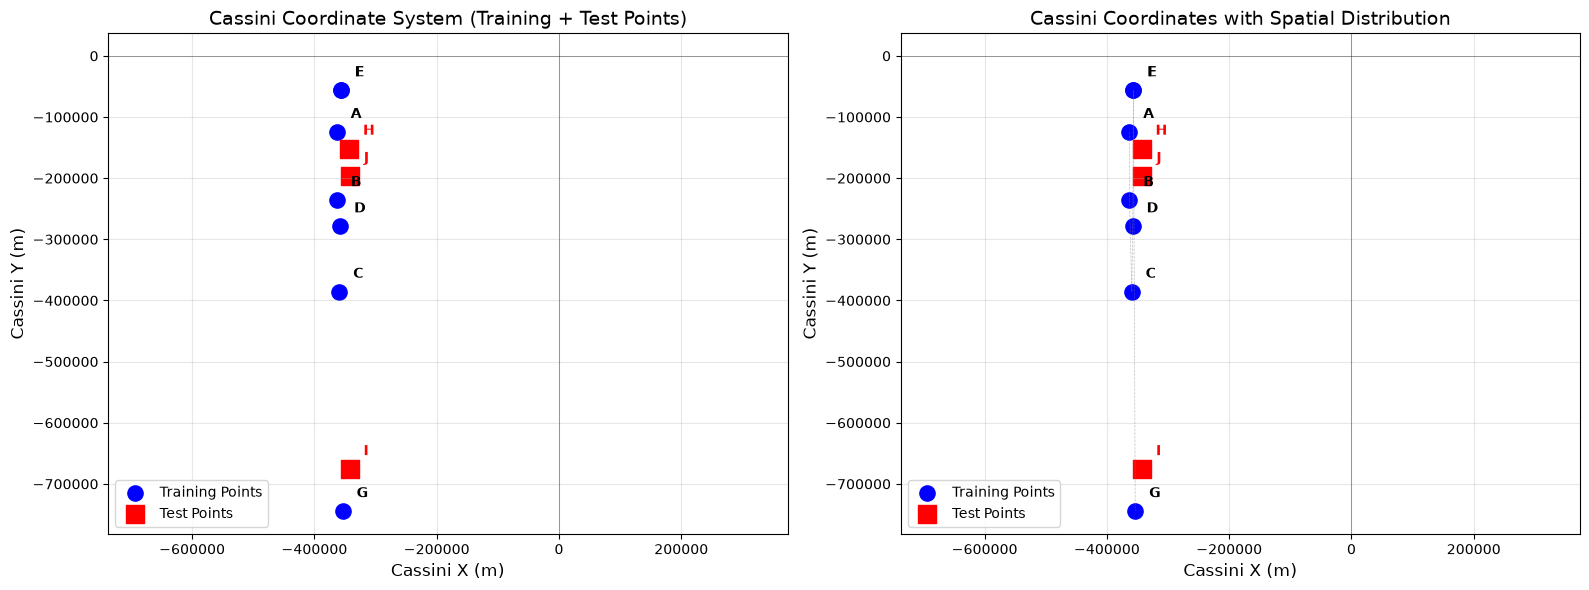

In [14]:
# Task 9: Visualize the Cassini coordinates using Matplotlib

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: All Cassini coordinates
ax1.scatter(cassini_train[:, 0], cassini_train[:, 1], color='blue', s=120, label='Training Points', marker='o')
ax1.scatter(cassini_test[:, 0], cassini_test[:, 1], color='red', s=150, label='Test Points', marker='s')

# Add labels for training points
for i, label in enumerate(train_labels):
    ax1.annotate(label, (cassini_train[i, 0], cassini_train[i, 1]), 
                xytext=(10, 10), textcoords='offset points', fontsize=10, fontweight='bold')

# Add labels for test points
for i, label in enumerate(test_labels):
    ax1.annotate(label, (cassini_test[i, 0], cassini_test[i, 1]), 
                xytext=(10, 10), textcoords='offset points', color='red', fontsize=10, fontweight='bold')

ax1.set_xlabel('Cassini X (m)', fontsize=12)
ax1.set_ylabel('Cassini Y (m)', fontsize=12)
ax1.set_title('Cassini Coordinate System (Training + Test Points)', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best')
ax1.axis('equal')
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax1.axvline(x=0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)

# Plot 2: Cassini coordinates with connections
ax2.scatter(cassini_train[:, 0], cassini_train[:, 1], color='blue', s=120, label='Training Points', marker='o')
ax2.scatter(cassini_test[:, 0], cassini_test[:, 1], color='red', s=150, label='Test Points', marker='s')

# Connect training points in order to show spatial distribution
for i in range(len(cassini_train) - 1):
    ax2.plot([cassini_train[i, 0], cassini_train[i+1, 0]], 
             [cassini_train[i, 1], cassini_train[i+1, 1]], 
             'gray', linestyle='--', alpha=0.5, linewidth=0.5)

# Add labels
for i, label in enumerate(train_labels):
    ax2.annotate(label, (cassini_train[i, 0], cassini_train[i, 1]), 
                xytext=(10, 10), textcoords='offset points', fontsize=10, fontweight='bold')

for i, label in enumerate(test_labels):
    ax2.annotate(label, (cassini_test[i, 0], cassini_test[i, 1]), 
                xytext=(10, 10), textcoords='offset points', color='red', fontsize=10, fontweight='bold')

ax2.set_xlabel('Cassini X (m)', fontsize=12)
ax2.set_ylabel('Cassini Y (m)', fontsize=12)
ax2.set_title('Cassini Coordinates with Spatial Distribution', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best')
ax2.axis('equal')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)
ax2.axvline(x=0, color='black', linestyle='-', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.show()

# Visualize the UTM coordinates
## Explanation:
## This visualization shows the transformation results:
    1. Left plot: Shows training points (blue), actual test points (red), and computed test points (orange) in UTM system
    2. Right plot: Zoomed view of test points with error lines
### The error lines (dashed gray) visually show the discrepancy between actual and computed positions for each test point.

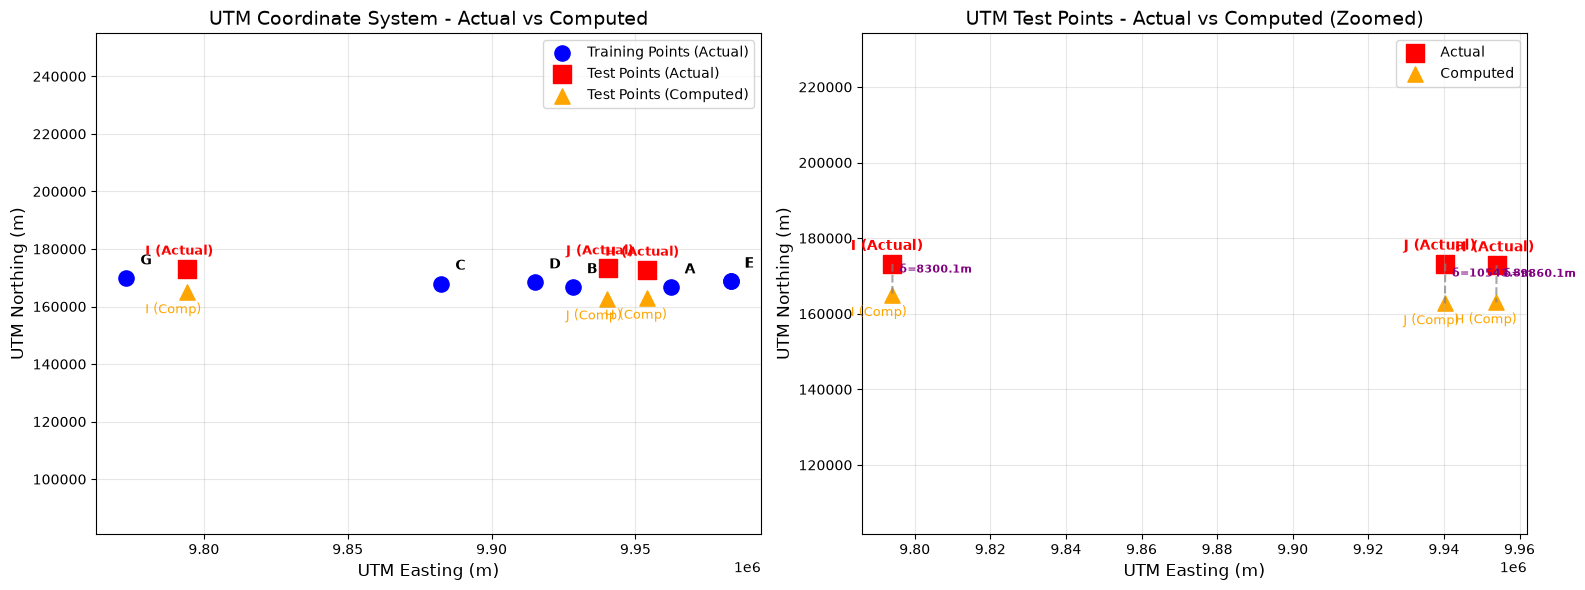

In [15]:
# Task 10: Visualize the UTM coordinates

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: UTM coordinates
ax1.scatter(utm_train[:, 0], utm_train[:, 1], color='blue', s=120, label='Training Points (Actual)', marker='o')
ax1.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Test Points (Actual)', marker='s')
ax1.scatter(utm_computed[:, 0], utm_computed[:, 1], color='orange', s=120, label='Test Points (Computed)', marker='^')

# Add labels
for i, label in enumerate(train_labels):
    ax1.annotate(label, (utm_train[i, 0], utm_train[i, 1]), 
                xytext=(10, 10), textcoords='offset points', fontsize=10, fontweight='bold')

for i, label in enumerate(test_labels):
    ax1.annotate(f'{label} (Actual)', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontsize=9, fontweight='bold')
    ax1.annotate(f'{label} (Comp)', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(-30, -15), textcoords='offset points', color='orange', fontsize=9)

ax1.set_xlabel('UTM Easting (m)', fontsize=12)
ax1.set_ylabel('UTM Northing (m)', fontsize=12)
ax1.set_title('UTM Coordinate System - Actual vs Computed', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best')
ax1.axis('equal')

# Plot 2: UTM Test Points Zoomed
ax2.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Actual', marker='s')
ax2.scatter(utm_computed[:, 0], utm_computed[:, 1], color='orange', s=120, label='Computed', marker='^')

# Add error lines
for i in range(len(utm_test)):
    ax2.plot([utm_test[i, 0], utm_computed[i, 0]], 
             [utm_test[i, 1], utm_computed[i, 1]], 
             'gray', linestyle='--', alpha=0.7, linewidth=1.5)

for i, label in enumerate(test_labels):
    ax2.annotate(f'{label} (Actual)', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontsize=10, fontweight='bold')
    ax2.annotate(f'{label} (Comp)', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(-30, -15), textcoords='offset points', color='orange', fontsize=9)
    # Add error magnitude annotation
    ax2.annotate(f'δ={horizontal_errors[i]:.1f}m', 
                ((utm_test[i, 0] + utm_computed[i, 0])/2, 
                 (utm_test[i, 1] + utm_computed[i, 1])/2),
                xytext=(5, 5), textcoords='offset points', 
                fontsize=8, color='purple', fontweight='bold')

ax2.set_xlabel('UTM Easting (m)', fontsize=12)
ax2.set_ylabel('UTM Northing (m)', fontsize=12)
ax2.set_title('UTM Test Points - Actual vs Computed (Zoomed)', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best')
ax2.axis('equal')

plt.tight_layout()
plt.show()

# Plot the actual and computed points together
## Explanation:
## This combined visualization shows:
     1. Left plot: All points (training and test) in one view
     2. Right plot: Test points with error bars and annotations
## The green triangles (computed) and red squares (actual) for test points are plotted together, making it easy to visually assess the transformation accuracy at a glance.

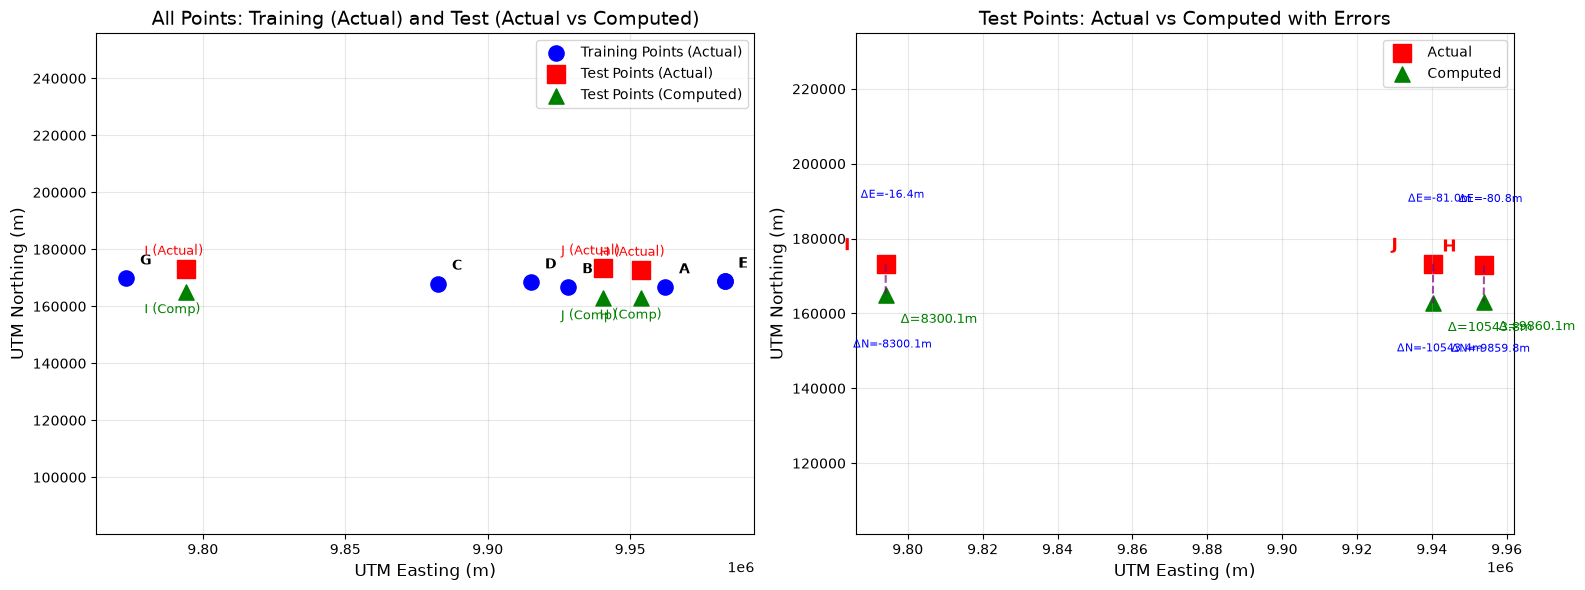

In [16]:
# Task 11: Plot the actual and computed points together

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: All points combined
ax1.scatter(utm_train[:, 0], utm_train[:, 1], color='blue', s=120, label='Training Points (Actual)', marker='o')
ax1.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Test Points (Actual)', marker='s')
ax1.scatter(utm_computed[:, 0], utm_computed[:, 1], color='green', s=120, label='Test Points (Computed)', marker='^')

# Add labels for all points
for i, label in enumerate(train_labels):
    ax1.annotate(label, (utm_train[i, 0], utm_train[i, 1]), 
                xytext=(10, 10), textcoords='offset points', fontsize=10, fontweight='bold')

for i, label in enumerate(test_labels):
    ax1.annotate(f'{label} (Actual)', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontsize=9)
    ax1.annotate(f'{label} (Comp)', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(-30, -15), textcoords='offset points', color='green', fontsize=9)

ax1.set_xlabel('UTM Easting (m)', fontsize=12)
ax1.set_ylabel('UTM Northing (m)', fontsize=12)
ax1.set_title('All Points: Training (Actual) and Test (Actual vs Computed)', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best')
ax1.axis('equal')

# Plot 2: Test points with error analysis
ax2.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Actual', marker='s')
ax2.scatter(utm_computed[:, 0], utm_computed[:, 1], color='green', s=120, label='Computed', marker='^')

# Draw error bars
for i in range(len(utm_test)):
    ax2.plot([utm_test[i, 0], utm_computed[i, 0]], 
             [utm_test[i, 1], utm_computed[i, 1]], 
             'purple', linestyle='--', alpha=0.7, linewidth=1.5)

# Add detailed annotations
for i, label in enumerate(test_labels):
    ax2.annotate(f'{label}', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontweight='bold', fontsize=12)
    ax2.annotate(f'  Δ={horizontal_errors[i]:.1f}m', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(5, -20), textcoords='offset points', color='green', fontsize=9)
    
    # Add residual components
    ax2.annotate(f'ΔE={errors[i][0]:.1f}m', 
                ((utm_test[i, 0] + utm_computed[i, 0])/2, 
                 (utm_test[i, 1] + utm_computed[i, 1])/2 + 20000),
                xytext=(5, 5), textcoords='offset points', 
                fontsize=8, color='blue', ha='center')
    ax2.annotate(f'ΔN={errors[i][1]:.1f}m', 
                ((utm_test[i, 0] + utm_computed[i, 0])/2, 
                 (utm_test[i, 1] + utm_computed[i, 1])/2 - 20000),
                xytext=(5, 5), textcoords='offset points', 
                fontsize=8, color='blue', ha='center')

ax2.set_xlabel('UTM Easting (m)', fontsize=12)
ax2.set_ylabel('UTM Northing (m)', fontsize=12)
ax2.set_title('Test Points: Actual vs Computed with Errors', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best')
ax2.axis('equal')

plt.tight_layout()
plt.show()

# Draw the residual vector using plt.quiver() or plt.arrow()

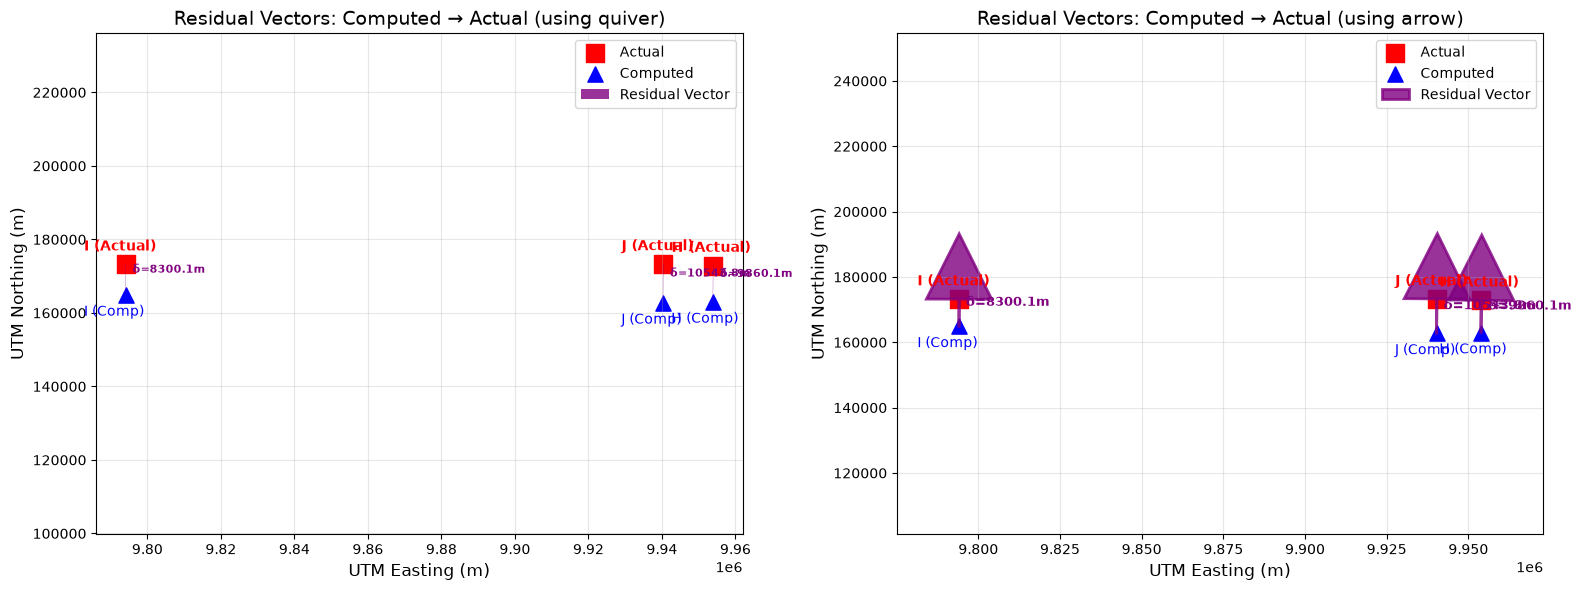

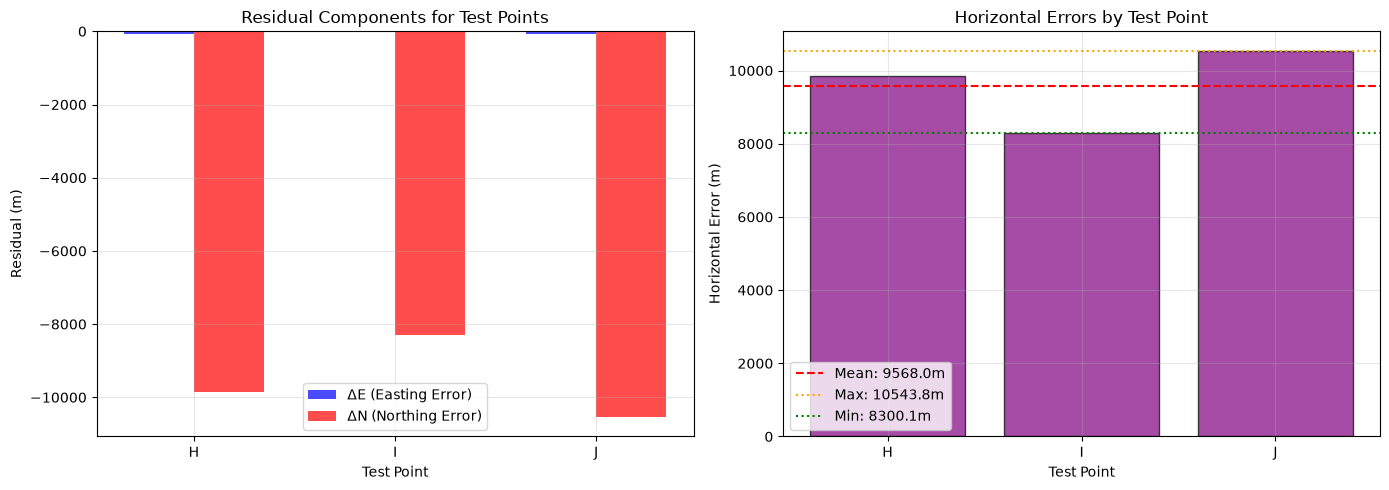

In [17]:
# Task 12: Draw the residual vector using plt.quiver() or plt.arrow()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Using quiver for residual vectors
ax1.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Actual', marker='s')
ax1.scatter(utm_computed[:, 0], utm_computed[:, 1], color='blue', s=120, label='Computed', marker='^')

# Draw residual vectors using quiver
for i in range(len(utm_test)):
    # Vector from computed to actual (residual)
    dx = utm_test[i, 0] - utm_computed[i, 0]  # ΔE (actual - computed)
    dy = utm_test[i, 1] - utm_computed[i, 1]  # ΔN (actual - computed)
    
    # Use quiver to draw vector from computed to actual
    ax1.quiver(utm_computed[i, 0], utm_computed[i, 1], dx, dy, 
               angles='xy', scale_units='xy', scale=1, 
               color='purple', alpha=0.8, width=0.0005, 
               label='Residual Vector' if i == 0 else '')

# Add labels
for i, label in enumerate(test_labels):
    ax1.annotate(f'{label} (Actual)', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontweight='bold')
    ax1.annotate(f'{label} (Comp)', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(-30, -15), textcoords='offset points', color='blue')

# Add vector magnitudes
for i in range(len(utm_test)):
    mid_x = (utm_test[i, 0] + utm_computed[i, 0]) / 2
    mid_y = (utm_test[i, 1] + utm_computed[i, 1]) / 2
    ax1.annotate(f'δ={horizontal_errors[i]:.1f}m', (mid_x, mid_y),
                xytext=(5, 5), textcoords='offset points', 
                fontsize=8, color='purple', fontweight='bold')

ax1.set_xlabel('UTM Easting (m)', fontsize=12)
ax1.set_ylabel('UTM Northing (m)', fontsize=12)
ax1.set_title('Residual Vectors: Computed → Actual (using quiver)', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best')
ax1.axis('equal')

# Plot 2: Using arrows for residual vectors
ax2.scatter(utm_test[:, 0], utm_test[:, 1], color='red', s=150, label='Actual', marker='s')
ax2.scatter(utm_computed[:, 0], utm_computed[:, 1], color='blue', s=120, label='Computed', marker='^')

# Draw residual vectors using arrow
for i in range(len(utm_test)):
    dx = utm_test[i, 0] - utm_computed[i, 0]
    dy = utm_test[i, 1] - utm_computed[i, 1]
    
    # Scale arrow length for better visualization
    ax2.arrow(utm_computed[i, 0], utm_computed[i, 1], dx, dy, 
              head_width=20000, head_length=20000, fc='purple', ec='purple', 
              alpha=0.8, linewidth=2,
              label='Residual Vector' if i == 0 else '')
    
    # Add magnitude annotation with offset
    mid_x = (utm_test[i, 0] + utm_computed[i, 0]) / 2
    mid_y = (utm_test[i, 1] + utm_computed[i, 1]) / 2
    ax2.annotate(f'δ={horizontal_errors[i]:.1f}m', (mid_x, mid_y),
                xytext=(5, 5), textcoords='offset points', 
                fontsize=9, color='purple', fontweight='bold')

for i, label in enumerate(test_labels):
    ax2.annotate(f'{label} (Actual)', (utm_test[i, 0], utm_test[i, 1]), 
                xytext=(-30, 10), textcoords='offset points', color='red', fontweight='bold')
    ax2.annotate(f'{label} (Comp)', (utm_computed[i, 0], utm_computed[i, 1]), 
                xytext=(-30, -15), textcoords='offset points', color='blue')

ax2.set_xlabel('UTM Easting (m)', fontsize=12)
ax2.set_ylabel('UTM Northing (m)', fontsize=12)
ax2.set_title('Residual Vectors: Computed → Actual (using arrow)', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best')
ax2.axis('equal')

plt.tight_layout()
plt.show()

# Additional residual analysis plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Residual components as bar chart
x_pos = np.arange(len(test_labels))
width = 0.35

ax1.bar(x_pos - width/2, [e[0] for e in errors], width, 
        label='ΔE (Easting Error)', color='blue', alpha=0.7)
ax1.bar(x_pos + width/2, [e[1] for e in errors], width, 
        label='ΔN (Northing Error)', color='red', alpha=0.7)

ax1.set_xlabel('Test Point')
ax1.set_ylabel('Residual (m)')
ax1.set_title('Residual Components for Test Points')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(test_labels)
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Horizontal error comparison
ax2.bar(test_labels, horizontal_errors, color='purple', alpha=0.7, edgecolor='black')
ax2.axhline(y=np.mean(horizontal_errors), color='red', linestyle='--', label=f'Mean: {np.mean(horizontal_errors):.1f}m')
ax2.axhline(y=np.max(horizontal_errors), color='orange', linestyle=':', label=f'Max: {np.max(horizontal_errors):.1f}m')
ax2.axhline(y=np.min(horizontal_errors), color='green', linestyle=':', label=f'Min: {np.min(horizontal_errors):.1f}m')

ax2.set_xlabel('Test Point')
ax2.set_ylabel('Horizontal Error (m)')
ax2.set_title('Horizontal Errors by Test Point')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Display results in a Pandas DataFrame

In [18]:
# Task 13: Display results in a Pandas DataFrame

# Create DataFrames for comprehensive results

# Training data
df_train = pd.DataFrame({
    'Point': train_labels,
    'Cassini_X': cassini_train[:, 0],
    'Cassini_Y': cassini_train[:, 1],
    'UTM_E_actual': utm_train[:, 0],
    'UTM_N_actual': utm_train[:, 1]
})

# Test data with results
df_test = pd.DataFrame({
    'Point': test_labels,
    'Cassini_X': cassini_test[:, 0],
    'Cassini_Y': cassini_test[:, 1],
    'UTM_E_actual': utm_test[:, 0],
    'UTM_N_actual': utm_test[:, 1],
    'UTM_E_computed': utm_computed[:, 0],
    'UTM_N_computed': utm_computed[:, 1],
    'ΔE (m)': [e[0] for e in errors],
    'ΔN (m)': [e[1] for e in errors],
    'Horizontal_Error (m)': horizontal_errors
})

# Transformation parameters
df_params = pd.DataFrame({
    'Parameter': ['a', 'b', 'Tx', 'Ty', 'Scale', 'Rotation (deg)'],
    'Value': [a, b, Tx, Ty, scale, theta_deg]
})

print("-" * 80)
print("TASK 13: DISPLAY RESULTS IN A PANDAS DATAFRAME")
print("-" * 80)

print("\nTRAINING DATA")
print("-" * 70)
print(df_train.to_string(index=False))

print("\n\nTRANSFORMATION PARAMETERS")
print("-" * 60)
print(df_params.to_string(index=False))

print("\n\nTEST DATA WITH RESULTS")
print("-" * 90)
print(df_test.to_string(index=False))

print("\n\nACCURACY STATISTICS")
print("-" * 60)
accuracy_stats = pd.DataFrame({
    'Metric': ['RMSE_E', 'RMSE_N', 'RMSE (Total)', 'Mean Horizontal Error', 
               'Std Dev Horizontal Error', 'Max Horizontal Error', 'Min Horizontal Error'],
    'Value (m)': [rmse_e, rmse_n, rmse_total, np.mean(horizontal_errors),
                  np.std(horizontal_errors), np.max(horizontal_errors), np.min(horizontal_errors)]
})
print(accuracy_stats.to_string(index=False))

--------------------------------------------------------------------------------
TASK 13: DISPLAY RESULTS IN A PANDAS DATAFRAME
--------------------------------------------------------------------------------

TRAINING DATA
----------------------------------------------------------------------
Point  Cassini_X  Cassini_Y  UTM_E_actual  UTM_N_actual
    A  -363303.9  -124356.2     9962251.2      166700.7
    B  -363127.9  -235694.9     9928288.3      166764.6
    C  -359263.6  -385586.0     9882566.3      167967.4
    D  -357677.4  -278604.1     9915200.1      168433.2
    E  -356566.9   -56019.3     9983096.8      168753.0
    F  -356564.3   -56012.2     9983099.0      168753.8
    G  -353603.5  -744433.2     9773106.3      169798.0


TRANSFORMATION PARAMETERS
------------------------------------------------------------
     Parameter         Value
             a -4.131709e-03
             b -3.049000e-01
            Tx  9.998666e+06
            Ty  5.772404e+04
         Scale  3.04928

# Allow user coordinate input

In [ ]:
# Task 14: Allow user coordinate input

def interactive_transform():
    """
    Interactive function to transform user-input Cassini coordinates to UTM.
    """
    print("\n" + "-" * 60)
    print("TASK 14: ALLOW USER COORDINATE INPUT")
    print("-" * 60)
    print("\nINTERACTIVE COORDINATE TRANSFORMATION")
    print("-" * 60)
    print("Enter Cassini coordinates to transform to UTM using the computed parameters:")
    print(f"Scale = {scale:.6f}, Rotation = {theta_deg:.4f}°")
    print(f"Translation: Tx = {Tx:.4f}, Ty = {Ty:.4f}")
    print("-" * 60)
    
    while True:
        try:
            x_input = input("\nEnter Cassini X coordinate (or 'q' to quit): ")
            if x_input.lower() == 'q':
                break
            
            y_input = input("Enter Cassini Y coordinate: ")
            
            x = float(x_input)
            y = float(y_input)
            
            E, N = transform_point(x, y, a, b, Tx, Ty)
            
            print(f"\nResults:")
            print(f"  Cassini: ({x:.4f}, {y:.4f})")
            print(f"  UTM:     ({E:.4f}, {N:.4f})")
            print("-" * 60)
            
        except ValueError:
            print("Invalid input. Please enter numeric values.")
        except Exception as e:
            print(f"Error: {e}")

# Run interactive transformation
interactive_transform()


------------------------------------------------------------
TASK 14: ALLOW USER COORDINATE INPUT
------------------------------------------------------------

INTERACTIVE COORDINATE TRANSFORMATION
------------------------------------------------------------
Enter Cassini coordinates to transform to UTM using the computed parameters:
Scale = 0.304928, Rotation = -90.7764°
Translation: Tx = 9998666.3261, Ty = 57724.0394
------------------------------------------------------------
